In [88]:
import os

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
import torch.utils.data as data
import torchvision.transforms as transforms
import torch.nn.functional as F
from pydicom import Dataset
from PIL import Image
from tqdm import tqdm

from src.utils.dataloader import BreastMNISTLoader, BCDRLoader, BUSBRALoader, INbreastLoader
from src.models.main.quantum import (
    QuantumModel,
    QuantumModelWithEncoder,
    ExtentedQuantumModelWithEncoder,
    ExtentedQuantumModel,
    SimpleQuantumModel,
    SimpleQuantumModelWithEncoder
)
from src.utils.training import (
    training_loop,
    test_model,
)

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score, roc_curve, auc

In [89]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if torch.cuda.is_available():
    print(f"Using: {torch.cuda.get_device_name(0)}")
    print(f"CUDA: {torch.version.cuda}")
else:
    print("CUDA is not available. Using CPU.")

Using: NVIDIA GeForce RTX 4070 Ti SUPER
CUDA: 12.4


In [90]:
loader = BreastMNISTLoader(
            batch_size=16, 
            image_size=224,
        )

train_loader, test_loader, val_loader = loader.get_dataloaders()
dataloader = {"train": train_loader, "val": val_loader, "test": test_loader}

Using downloaded and verified file: /home/eflammere/.medmnist/breastmnist_224.npz
Using downloaded and verified file: /home/eflammere/.medmnist/breastmnist_224.npz
Using downloaded and verified file: /home/eflammere/.medmnist/breastmnist_224.npz


In [91]:
# busbra_loader = BUSBRALoader(
#     batch_size=16,
#     image_size=28,
#     root_dir='src/data/BUSBRA/png'
# )

# busbra_train_loader, busbra_test_loader, busbra_val_loader = busbra_loader.get_dataloaders()
# busbra_dataloader = {"train": busbra_train_loader, "val": busbra_val_loader, "test": busbra_test_loader}

# print(f"BUSBRA Dataset loaded:")
# print(f"  Train samples: {len(busbra_train_loader.dataset)}")
# print(f"  Val samples: {len(busbra_val_loader.dataset)}")
# print(f"  Test samples: {len(busbra_test_loader.dataset)}")

In [92]:
# inbreast_loader = INbreastLoader(
#     batch_size=16,
#     image_size=224,
#     root_dir='src/data/INbreast/png'
# )

# inbreast_train_loader, inbreast_val_loader, inbreast_test_loader = inbreast_loader.get_dataloaders()
# inbreast_dataloader = {"train": inbreast_train_loader, "val": inbreast_val_loader, "test": inbreast_test_loader}

# print(f"INbreast Dataset loaded:")
# print(f"  Train samples: {len(inbreast_train_loader.dataset)}")
# print(f"  Validation samples: {len(inbreast_val_loader.dataset)}")
# print(f"  Test samples: {len(inbreast_test_loader.dataset)}")


In [93]:
# bcdr_loader = BCDRLoader(
#     batch_size=16,
#     image_size=224,
#     root_dir='src/data/BCDR/png'
# )

# bcdr_train_loader, bcdr_test_loader, bcdr_val_loader = bcdr_loader.get_dataloaders()
# bcdr_dataloader = {"train": bcdr_train_loader, "val": bcdr_val_loader, "test": bcdr_test_loader}

# print(f"BCDR Dataset loaded:")
# print(f"  Train samples: {len(bcdr_train_loader.dataset)}")
# print(f"  Val samples: {len(bcdr_val_loader.dataset)}")
# print(f"  Test samples: {len(bcdr_test_loader.dataset)}")

# # Check class distribution
# train_labels = [label for _, label in bcdr_train_loader.dataset]
# unique, counts = np.unique(train_labels, return_counts=True)
# print(f"\nTrain class distribution:")
# for cls, count in zip(unique, counts):
#     print(f"  Class {cls}: {count} ({count/len(train_labels)*100:.1f}%)")

# val_labels = [label for _, label in bcdr_val_loader.dataset]
# unique_val, counts_val = np.unique(val_labels, return_counts=True)
# print(f"\nVal class distribution:")
# for cls, count in zip(unique_val, counts_val):
#     print(f"  Class {cls}: {count} ({count/len(val_labels)*100:.1f}%)")

In [94]:
n_qubits = 4
n_layers = 1
rand_params = np.random.uniform(high=2 * np.pi, size=(n_layers, n_qubits))
num_classes = 2
patch_size = 4 # 4 ou 2
output_size = (14, 14)

In [95]:
# from src.models.preprocessing.autoencoder import Autoencoder

# autoencoder_path = "/home/eflammere/HybridEmbeddingsForBreastCancerDetection/experiments/models/autoencoder/autoencoder_testes_busbra_latent3.pth"
# autoencoder = Autoencoder(input_channels=1, latent_channels=3, output_channels=1)
# autoencoder.load_state_dict(torch.load(autoencoder_path, map_location=device))

In [96]:
from src.models.preprocessing.skip import Autoencoder

autoencoder_path = "/home/eflammere/HybridEmbeddingsForBreastCancerDetection/experiments/models/unet_autoencoder/unet_autoencoder_testes_breastmnist_latent64.pth"
autoencoder = Autoencoder(input_channels=1, latent_channels=64)
autoencoder.load_state_dict(torch.load(autoencoder_path, map_location=device))

/tmp/ipykernel_48065/2674843272.py:5: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  autoencoder.load_state_dict(torch.load(autoencoder_path, map_location=device))


<All keys matched successfully>

## 1. QuantumModel (Non-trainable quantum circuit without encoder)

In [97]:
model_basic = QuantumModel(
    n_qubits=n_qubits,
    n_layers=n_layers,
    rand_params=rand_params,
    output_size=output_size,
    patch_size=patch_size,
    num_classes=num_classes
).to(device)

print(f"QuantumModel created with {sum(p.numel() for p in model_basic.parameters())} parameters")

QuantumModel created with 0 parameters


## 2. QuantumModelWithEncoder (Non-trainable quantum with autoencoder)

In [98]:
model_with_encoder = QuantumModelWithEncoder(
    autoencoder=autoencoder,
    n_qubits=n_qubits,
    n_layers=n_layers,
    rand_params=rand_params,
    latent_channels=3,
    output_size=output_size,
    patch_size=patch_size,
    num_classes=num_classes
).to(device)

print(f"QuantumModelWithEncoder created with {sum(p.numel() for p in model_with_encoder.parameters() if p.requires_grad)} trainable parameters")

QuantumModelWithEncoder created with 0 trainable parameters


## 3. ExtentedQuantumModel (Trainable quantum circuit without encoder)

In [99]:
model_trainable = ExtentedQuantumModel(
    n_qubits=n_qubits,
    n_layers=n_layers,
    num_classes=num_classes,
    patch_size=patch_size,
    mode="matmul",
    stride=None,
    use_parallel=True
).to(device)

print(f"ExtentedQuantumModel created")

Quantum layer has 4 trainable parameters
Requires grad: True
ExtentedQuantumModel created


## 4. ExtentedQuantumModelWithEncoder (Trainable quantum with autoencoder)

In [100]:
model_trainable_encoder = ExtentedQuantumModelWithEncoder(
    n_qubits=n_qubits,
    n_layers=n_layers,
    num_classes=num_classes,
    patch_size=patch_size,
    encoder=autoencoder,
    encoder_output_size=28,
    mode="matmul",  # Options: "2d", "sequential", "matmul"
    stride=None,
    use_parallel=True
).to(device)

print(f"ExtentedQuantumModelWithEncoder created")

Quantum layer has 4 trainable parameters
Requires grad: True
ExtentedQuantumModelWithEncoder created


## Select Model for Training

Choose which model to use by uncommenting one of the lines below:

In [101]:
# Select one model for training:
# model = model_basic  # Non-trainable quantum without encoder
# model = model_with_encoder  # Non-trainable quantum with autoencoder
# model = model_trainable  # Trainable quantum without encoder (3 FC layers)
model = model_trainable_encoder  # Trainable quantum with autoencoder (3 FC layers)

print(f"\nSelected model: {model.__class__.__name__}")
print(f"Total parameters: {sum(p.numel() for p in model.parameters())}")
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad)}")


Selected model: ExtentedQuantumModelWithEncoder
Total parameters: 1896821
Trainable parameters: 4


## Training Configuration

In [ ]:
# Training hyperparameters
num_epochs = 10
learning_rate = 1e-3
save_dir = "results/models/unet_encoder/quantum_model_trainable_1d/"
os.makedirs(save_dir, exist_ok=True)

# Initialize FC layer with dummy forward pass (for non-trainable models)
if isinstance(model, (QuantumModel, QuantumModelWithEncoder)):
    with torch.no_grad():
        dummy_input = torch.randn(1, 1, 224, 224).to(device)
        _ = model(dummy_input)
    print("✓ Model FC layer initialized")

# Loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(
    model.parameters(),
    lr=learning_rate
)

print(f"\nTraining configuration:")
print(f"  Epochs: {num_epochs}")
print(f"  Learning rate: {learning_rate}")
print(f"  Optimizer: Adam")
print(f"  Loss function: CrossEntropyLoss")
print(f"  Save directory: {save_dir}")


Training configuration:
  Epochs: 10
  Learning rate: 0.001
  Optimizer: Adam
  Loss function: CrossEntropyLoss
  Save directory: results/models/unet_encoder/quantum_model_trainable_2d/


In [103]:
history = training_loop(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    device=device,
    num_epochs=num_epochs,
    save_dir=save_dir,
    save_best_only=True,
    save_all_epochs=True,
)

print("\n✓ Training completed!")

Epoch 1/10


KeyboardInterrupt: 

Generating predictions: 100%|██████████| 10/10 [00:08<00:00,  1.14it/s]


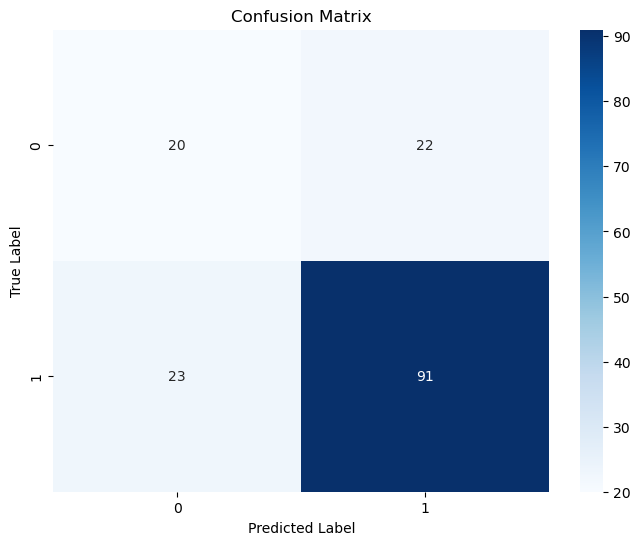

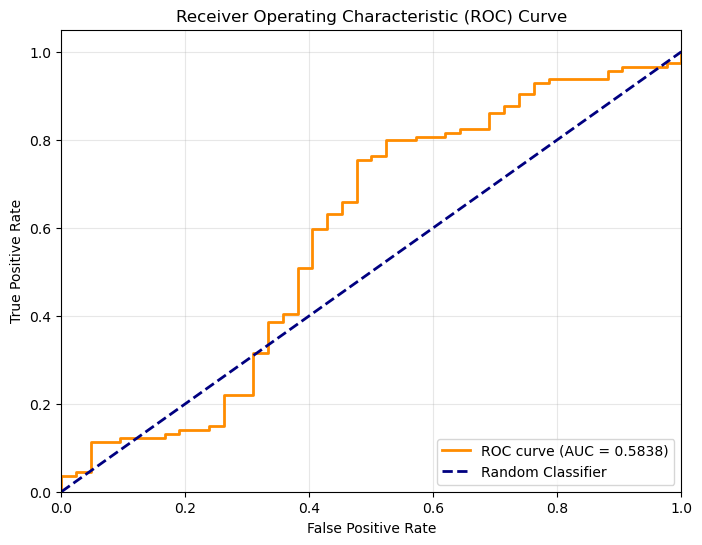


✓ Visualizations complete!


In [ ]:
# Generate predictions for visualization
model.eval()
all_labels = []
all_predictions = []
all_probs = []

with torch.no_grad():
    for images, labels in tqdm(test_loader, desc="Generating predictions"):
        images = images.to(device)
        labels = labels.squeeze().to(device)
        
        outputs = model(images)
        probs = torch.softmax(outputs, dim=1)[:, 1].cpu().numpy()
        
        all_probs.extend(probs)
        all_predictions.extend(outputs.argmax(dim=1).cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# Confusion Matrix
cm = confusion_matrix(all_labels, all_predictions)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=True)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

# ROC Curve
fpr, tpr, thresholds = roc_curve(all_labels, all_probs)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Classifier')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

print(f"\n✓ Visualizations complete!")

## Confusion Matrix and ROC Curve

In [ ]:
# Initialize the model layers with a dummy forward pass first
print("Initializing model layers...")
model.eval()  # Set to eval mode to avoid BatchNorm issues with batch_size=1
with torch.no_grad():
    dummy_input = torch.randn(1, 1, 224, 224).to(device)
    _ = model(dummy_input)
print("✓ Model layers initialized")

best_model_path = os.path.join(save_dir, "checkpoints/model_epoch3.pth")
if os.path.exists(best_model_path):
    checkpoint = torch.load(best_model_path, map_location=device, weights_only=True)
    model.load_state_dict(checkpoint['model_state_dict'])
    print(f"✓ Loaded best model from {best_model_path}")
    print(f"  Epoch: {checkpoint.get('epoch', 'N/A')}")
    print(f"  Val Accuracy: {checkpoint.get('val_acc', 'N/A'):.4f}")
else:
    print("⚠ Best model not found, using current weights")

hyperparams = {
    "epochs": num_epochs,
    "batch_size": 16,
    "learning_rate": learning_rate,
    "n_qubits": n_qubits,
    "n_layers": n_layers,
    "patch_size": patch_size,
    "model": model.__class__.__name__
}

test_loss, test_acc, test_prec, test_rec, test_f1, test_auc = test_model(
    model=model,
    dataloader=test_loader,
    criterion=criterion,
    device=device,
    hyperparams=hyperparams,
    output_file="results.txt",
    extract_features=False,
    compute_detailed_metrics=True
)

print("\n" + "="*50)
print("FINAL TEST RESULTS")
print("="*50)
print(f"Test Loss:      {test_loss:.4f}")
print(f"Test Accuracy:  {test_acc:.4f}")
print(f"Test Precision: {test_prec:.4f}")
print(f"Test Recall:    {test_rec:.4f}")
print(f"Test F1 Score:  {test_f1:.4f}")
print(f"Test AUC:       {test_auc:.4f}")
print("="*50)

Initializing model layers...
✓ Model layers initialized
✓ Loaded best model from results/models/unet_encoder/quantum_model_trainable_2d/checkpoints/model_epoch3.pth
  Epoch: 2
  Val Accuracy: 0.8462


Testing: 100%|██████████| 10/10 [00:07<00:00,  1.27it/s]

Test Loss: 0.5228
Accuracy: 0.7500, Precision: 0.8099, Recall: 0.8596, F1: 0.8340, AUC: 0.7387
Macro - Precision: 0.6764, Recall: 0.6560, F1: 0.6638
Micro - Precision: 0.7500, Recall: 0.7500, F1: 0.7500

FINAL TEST RESULTS
Test Loss:      0.5228
Test Accuracy:  0.7500
Test Precision: 0.8099
Test Recall:    0.8596
Test F1 Score:  0.8340
Test AUC:       0.7387


## Test Model on Test Set

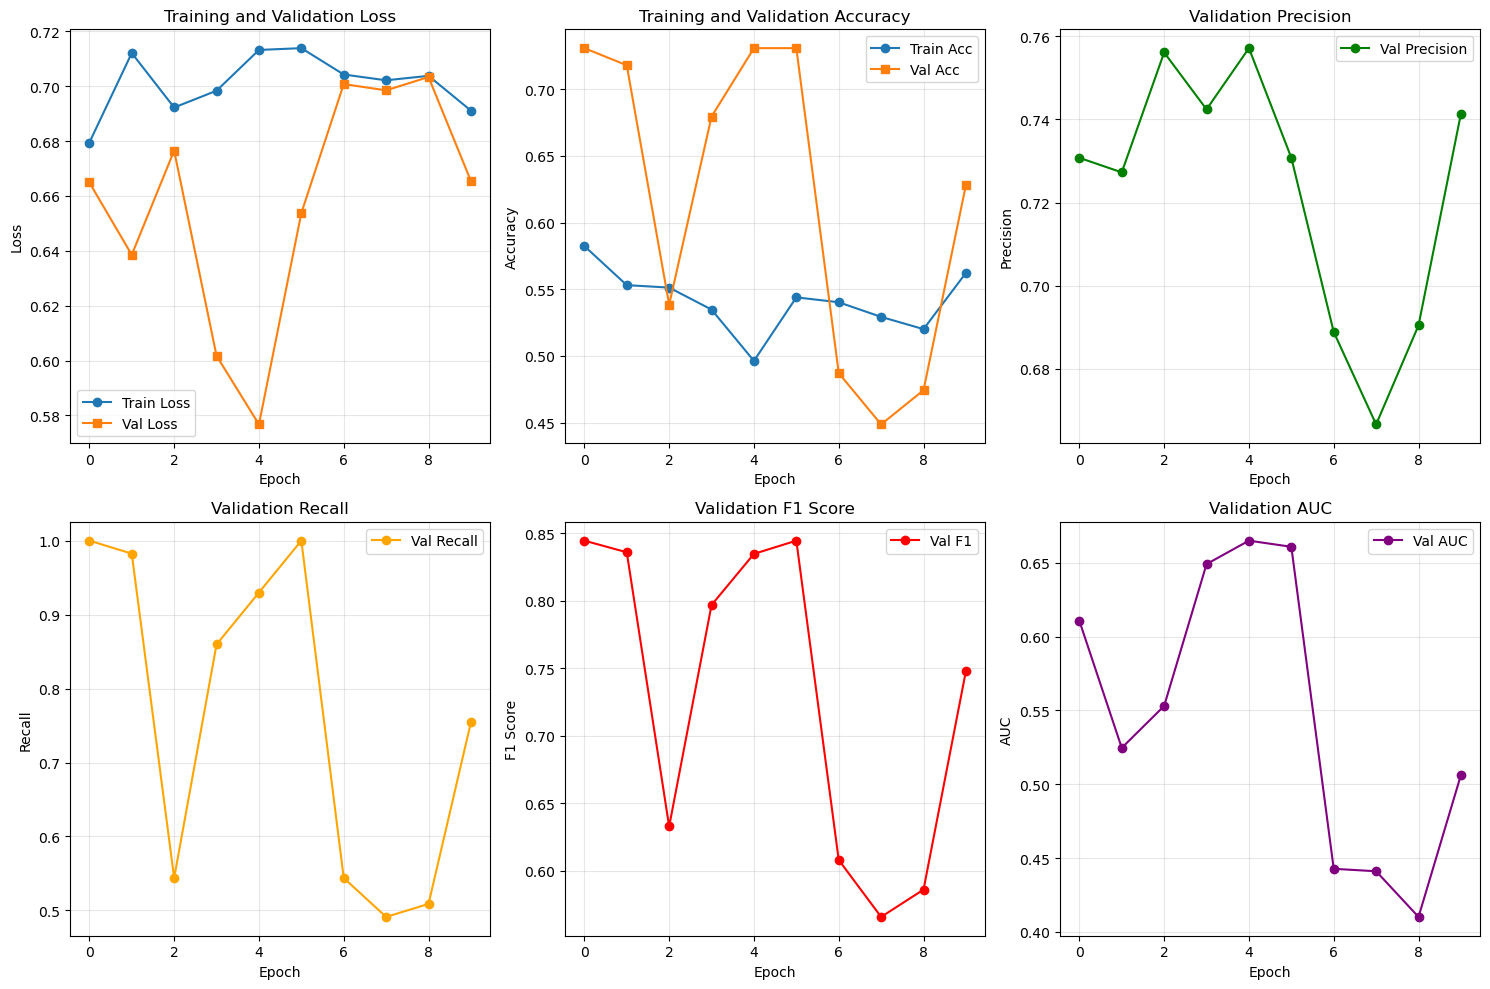

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

# Loss
axes[0, 0].plot(history['train_loss'], label='Train Loss', marker='o')
axes[0, 0].plot(history['val_loss'], label='Val Loss', marker='s')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Loss')
axes[0, 0].set_title('Training and Validation Loss')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# Accuracy
axes[0, 1].plot(history['train_acc'], label='Train Acc', marker='o')
axes[0, 1].plot(history['val_acc'], label='Val Acc', marker='s')
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('Accuracy')
axes[0, 1].set_title('Training and Validation Accuracy')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# Precision
axes[0, 2].plot(history['val_precision'], label='Val Precision', marker='o', color='green')
axes[0, 2].set_xlabel('Epoch')
axes[0, 2].set_ylabel('Precision')
axes[0, 2].set_title('Validation Precision')
axes[0, 2].legend()
axes[0, 2].grid(True, alpha=0.3)

# Recall
axes[1, 0].plot(history['val_recall'], label='Val Recall', marker='o', color='orange')
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('Recall')
axes[1, 0].set_title('Validation Recall')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# F1 Score
axes[1, 1].plot(history['val_f1'], label='Val F1', marker='o', color='red')
axes[1, 1].set_xlabel('Epoch')
axes[1, 1].set_ylabel('F1 Score')
axes[1, 1].set_title('Validation F1 Score')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

# AUC
axes[1, 2].plot(history['val_auc'], label='Val AUC', marker='o', color='purple')
axes[1, 2].set_xlabel('Epoch')
axes[1, 2].set_ylabel('AUC')
axes[1, 2].set_title('Validation AUC')
axes[1, 2].legend()
axes[1, 2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()